<a href="https://colab.research.google.com/github/theatu824/MSSP607-GitHub/blob/main/WeeklyModules/Week07/PARTICIPATION_ACTIVITY_Week_7_Export_a_bar_chart_from_a_data_frame_to_a_PDF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
from google.colab import userdata
import os
Git_Key = userdata.get('Git_Key')
owner = 'theatu824' # Replace with the GitHub repository owner
repository = 'MSSP607-GitHub' # Replace with the GitHub repository name
clone_url = f'https://{Git_Key}@github.com/{owner}/{repository}.git'
# Clone the repository
import subprocess
subprocess.run(['git', 'clone', clone_url])
# Navigate into the cloned repository directory (optional, but often useful)
os.chdir(repository)
print(f"Changed directory to: {os.getcwd()}")

Changed directory to: /content/MSSP607-GitHub


In [2]:
df = pd.read_csv(
    "data/InternetSales.csv",
    encoding="cp1252"
)
df.shape

/tmp/ipykernel_3455/303191344.py:1: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


(60398, 60)

In [3]:
df.head()

,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.15,1912.15,3399.99,272.00,85.00,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.62,1265.62,2319.99,185.60,58.00,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.22,8.22,21.98,1.76,0.55,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.94,1481.94,2384.07,190.73,59.60,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.84,10.84,28.99,2.32,0.72,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [4]:
df.columns.tolist()

['ID',
 'CustomerKey',
 'GeographyKey',
 'City',
 'CountryRegionCode',
 'EnglishCountryRegionName',
 'CustomerAlternateKey',
 'Title',
 'FirstName',
 'MiddleName',
 'LastName',
 'NameStyle',
 'BirthDate',
 'MaritalStatus',
 'Suffix',
 'Gender',
 'EmailAddress',
 'YearlyIncome',
 'TotalChildren',
 'NumberChildrenAtHome',
 'EnglishEducation',
 'SpanishEducation',
 'FrenchEducation',
 'EnglishOccupation',
 'SpanishOccupation',
 'FrenchOccupation',
 'HouseOwnerFlag',
 'NumberCarsOwned',
 'AddressLine1',
 'AddressLine2',
 'Phone',
 'DateFirstPurchase',
 'CommuteDistance',
 'ProductKey',
 'EnglishProductName',
 'OrderDateKey',
 'DueDateKey',
 'ShipDateKey',
 'CustomerKey.1',
 'PromotionKey',
 'CurrencyKey',
 'SalesTerritoryKey',
 'SalesOrderNumber',
 'SalesOrderLineNumber',
 'RevisionNumber',
 'OrderQuantity',
 'UnitPrice',
 'ExtendedAmount',
 'UnitPriceDiscountPct',
 'DiscountAmount',
 'ProductStandardCost',
 'TotalProductCost',
 'SalesAmount',
 'TaxAmt',
 'Freight',
 'CarrierTrackingNumber

In [5]:
df[["OrderDate", "SalesAmount"]].head()
df[["OrderDate", "SalesAmount"]].dtypes

,0
OrderDate,object
SalesAmount,float64


In [6]:
df["OrderDate"] = pd.to_datetime(
    df["OrderDate"],
    errors="coerce"
)
df["OrderDate"].dtype

dtype('<M8[ns]')

In [10]:
#create a bar chart of yearly sales
df["year"] = df["OrderDate"].dt.year
df["year"].value_counts()

,count
year,
2013,52801
2012,3397
2011,2216
2014,1970
2010,14


In [12]:
yearly_sales = (
    df.groupby("year")["SalesAmount"]
      .sum()
)
yearly_sales

,SalesAmount
year,
2010,43421.04
2011,7075525.93
2012,5842485.20
2013,16351550.34
2014,45694.72


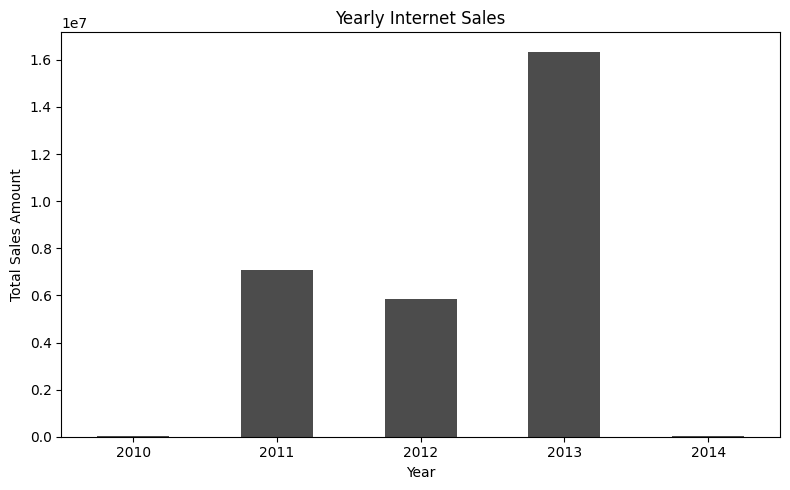

In [16]:
ax = yearly_sales.plot.bar(
    color="k",
    alpha=0.7,
    rot=0,
    figsize=(8, 5)
)
ax.set_title("Yearly Internet Sales")
ax.set_xlabel("Year")
ax.set_ylabel("Total Sales Amount")

fig = ax.figure
fig.tight_layout()

fig.savefig(
    "yearly_sales.pdf",
    format="pdf",
    bbox_inches="tight"
)
plt.show()